## 1. Setup & Reproducibility

In [1]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))



PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 2. Import Libraries



In [2]:
import os
import time
import copy
import random
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, models, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from IPython.display import display



## 3. Dataset Preparation




### Dataset download and class overview

In [3]:
from torchvision.datasets import OxfordIIITPet

# Download dataset
dataset = OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    download=True
)

print("Total images:", len(dataset))
print("Number of classes:", len(dataset.classes))
print("\nClasses:")

for idx, class_name in enumerate(dataset.classes):
    print(f"{idx:2d}: {class_name}")

100%|██████████| 792M/792M [00:30<00:00, 26.2MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 11.6MB/s]


Total images: 3680
Number of classes: 37

Classes:
 0: Abyssinian
 1: American Bulldog
 2: American Pit Bull Terrier
 3: Basset Hound
 4: Beagle
 5: Bengal
 6: Birman
 7: Bombay
 8: Boxer
 9: British Shorthair
10: Chihuahua
11: Egyptian Mau
12: English Cocker Spaniel
13: English Setter
14: German Shorthaired
15: Great Pyrenees
16: Havanese
17: Japanese Chin
18: Keeshond
19: Leonberger
20: Maine Coon
21: Miniature Pinscher
22: Newfoundland
23: Persian
24: Pomeranian
25: Pug
26: Ragdoll
27: Russian Blue
28: Saint Bernard
29: Samoyed
30: Scottish Terrier
31: Shiba Inu
32: Siamese
33: Sphynx
34: Staffordshire Bull Terrier
35: Wheaten Terrier
36: Yorkshire Terrier


### Select the 10 classes

In [4]:
# 5 cat breeds & 5 dog breeds
selected_classes = [
    "Abyssinian",
    "Bengal",
    "Birman",
    "Persian",
    "Siamese",
    "Beagle",
    "Boxer",
    "Chihuahua",
    "Pug",
    "Shiba Inu"
]

# Convert class names to original class indices
selected_class_indices = [
    dataset.classes.index(class_name)
    for class_name in selected_classes
]

print("Selected classes:")
for new_idx, class_name in enumerate(selected_classes):
    print(f"{new_idx}: {class_name}")

print("\nOriginal class indices:")
print(selected_class_indices)



Selected classes:
0: Abyssinian
1: Bengal
2: Birman
3: Persian
4: Siamese
5: Beagle
6: Boxer
7: Chihuahua
8: Pug
9: Shiba Inu

Original class indices:
[0, 5, 6, 23, 32, 4, 8, 10, 25, 31]


In [5]:
from torch.utils.data import Dataset, DataLoader, Subset, ConcatDataset

# Load both official splits
dataset_trainval = OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    download=True
)

dataset_test = OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    download=True
)

# Combine datasets
dataset = ConcatDataset([dataset_trainval, dataset_test])

# Combine labels in the same order as the concatenated dataset
all_labels = np.concatenate([
    np.asarray(dataset_trainval._labels),
    np.asarray(dataset_test._labels)
])

print("Total images:", len(dataset))
print("Total labels:", len(all_labels))
print("\nAvailable images per selected class:")

for class_idx, class_name in zip(
    selected_class_indices, selected_classes
):
    count = int(np.sum(all_labels == class_idx))
    print(f"{class_name}: {count}")

Total images: 7349
Total labels: 7349

Available images per selected class:
Abyssinian: 198
Bengal: 200
Birman: 200
Persian: 200
Siamese: 199
Beagle: 200
Boxer: 199
Chihuahua: 200
Pug: 200
Shiba Inu: 200


### Create the subset and stratified split

In [6]:
# Select all images belonging to the 10 selected classes
selected_indices = np.where(
    np.isin(all_labels, selected_class_indices)
)[0]

# Map original class indices to labels 0-9
class_mapping = {
    original_idx: new_idx
    for new_idx, original_idx in enumerate(selected_class_indices)
}

selected_labels_original = all_labels[selected_indices]

selected_labels = np.array([
    class_mapping[label]
    for label in selected_labels_original
])

print("Total selected images:", len(selected_indices))

# First split: 70% train, 30% temporary
train_indices, temp_indices = train_test_split(
    selected_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=selected_labels
)

# Get labels for the temporary subset
temp_labels = np.array([
    class_mapping[all_labels[idx]]
    for idx in temp_indices
])

# Second split: 15% validation, 15% test
val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

print("\nSplit results:")
print(f"Train: {len(train_indices)} images")
print(f"Validation: {len(val_indices)} images")
print(f"Test: {len(test_indices)} images")
print(f"Total: {len(train_indices) + len(val_indices) + len(test_indices)} images")

train_set = set(train_indices)
val_set = set(val_indices)
test_set = set(test_indices)

assert train_set.isdisjoint(val_set), "Train and validation overlap."
assert train_set.isdisjoint(test_set), "Train and test overlap."
assert val_set.isdisjoint(test_set), "Validation and test overlap."

assert len(selected_indices) == 1996
assert len(train_indices) + len(val_indices) + len(test_indices) == 1996

print("Leakage check passed: all split indices are disjoint.")

for split_name, split_indices in [
    ("Train", train_indices),
    ("Validation", val_indices),
    ("Test", test_indices)
]:
    split_labels = np.array([
        class_mapping[all_labels[idx]]
        for idx in split_indices
    ])

    counts = (
        pd.Series(split_labels)
        .value_counts()
        .reindex(range(len(selected_classes)), fill_value=0)
    )

    print(f"\n{split_name} class counts:")
    display(pd.DataFrame({
        "Class": selected_classes,
        "Count": counts.values
    }))

Total selected images: 1996

Split results:
Train: 1397 images
Validation: 299 images
Test: 300 images
Total: 1996 images
Leakage check passed: all split indices are disjoint.

Train class counts:


,Class,Count
0,Abyssinian,139
1,Bengal,140
2,Birman,140
3,Persian,140
4,Siamese,139
5,Beagle,140
6,Boxer,139
7,Chihuahua,140
8,Pug,140
9,Shiba Inu,140



Validation class counts:


,Class,Count
0,Abyssinian,29
1,Bengal,30
2,Birman,30
3,Persian,30
4,Siamese,30
5,Beagle,30
6,Boxer,30
7,Chihuahua,30
8,Pug,30
9,Shiba Inu,30



Test class counts:


,Class,Count
0,Abyssinian,30
1,Bengal,30
2,Birman,30
3,Persian,30
4,Siamese,30
5,Beagle,30
6,Boxer,30
7,Chihuahua,30
8,Pug,30
9,Shiba Inu,30


### Image transforms

In [7]:
weights = models.ResNet18_Weights.IMAGENET1K_V1

train_transform_no_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std
    )
])

train_transform_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std
    )
])

eval_transform = weights.transforms()

print("Transforms created successfully.")



Transforms created successfully.


### Dataset wrapper and split datasets

In [8]:

for split_name, split_indices in [
    ("Train", train_indices),
    ("Validation", val_indices),
    ("Test", test_indices)
]:
    labels = [
        class_mapping[int(all_labels[i])]
        for i in split_indices
    ]

    counts = (
        pd.Series(labels)
        .value_counts()
        .reindex(range(len(selected_classes)), fill_value=0)
    )

    print(f"\n{split_name} class distribution:")
    display(pd.DataFrame({
        "Label": range(len(selected_classes)),
        "Class": selected_classes,
        "Count": counts.values
    }))

    assert (counts > 0).all(), f"Missing class in {split_name}!"

print("\nAll 10 classes are present in every split.")


Train class distribution:


,Label,Class,Count
0,0,Abyssinian,139
1,1,Bengal,140
2,2,Birman,140
3,3,Persian,140
4,4,Siamese,139
5,5,Beagle,140
6,6,Boxer,139
7,7,Chihuahua,140
8,8,Pug,140
9,9,Shiba Inu,140



Validation class distribution:


,Label,Class,Count
0,0,Abyssinian,29
1,1,Bengal,30
2,2,Birman,30
3,3,Persian,30
4,4,Siamese,30
5,5,Beagle,30
6,6,Boxer,30
7,7,Chihuahua,30
8,8,Pug,30
9,9,Shiba Inu,30



Test class distribution:


,Label,Class,Count
0,0,Abyssinian,30
1,1,Bengal,30
2,2,Birman,30
3,3,Persian,30
4,4,Siamese,30
5,5,Beagle,30
6,6,Boxer,30
7,7,Chihuahua,30
8,8,Pug,30
9,9,Shiba Inu,30



All 10 classes are present in every split.


### DataLoaders

In [9]:

class RemappedOxfordIIITPet(Dataset):
    def __init__(self, base_dataset, indices, transform, all_labels, class_mapping):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform
        self.all_labels = all_labels
        self.class_mapping = class_mapping

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        original_idx = int(self.indices[idx])

        # ConcatDataset returns the image from the correct original split
        image, _ = self.base_dataset[original_idx]

        # Apply the selected transform
        if self.transform is not None:
            image = self.transform(image)

        # Remap original class label to 0-9
        original_label = int(self.all_labels[original_idx])
        new_label = self.class_mapping[original_label]

        return image, new_label


train_dataset = RemappedOxfordIIITPet(
    base_dataset=dataset,
    indices=train_indices,
    transform=train_transform_no_aug,
    all_labels=all_labels,
    class_mapping=class_mapping
)

val_dataset = RemappedOxfordIIITPet(
    base_dataset=dataset,
    indices=val_indices,
    transform=eval_transform,
    all_labels=all_labels,
    class_mapping=class_mapping
)

test_dataset = RemappedOxfordIIITPet(
    base_dataset=dataset,
    indices=test_indices,
    transform=eval_transform,
    all_labels=all_labels,
    class_mapping=class_mapping
)

print("Train dataset      :", len(train_dataset))
print("Validation dataset :", len(val_dataset))
print("Test dataset       :", len(test_dataset))

# Verify image tensors and remapped labels
sample_images, sample_labels = next(iter(
    DataLoader(train_dataset, batch_size=32, shuffle=False)
))

print("Image batch shape:", sample_images.shape)
print("Sample labels:", sample_labels.tolist())
print("Minimum label:", sample_labels.min().item())
print("Maximum label:", sample_labels.max().item())

Train dataset      : 1397
Validation dataset : 299
Test dataset       : 300
Image batch shape: torch.Size([32, 3, 224, 224])
Sample labels: [3, 0, 5, 5, 5, 6, 1, 2, 5, 5, 4, 0, 2, 4, 7, 5, 6, 5, 0, 5, 0, 8, 5, 4, 0, 0, 7, 7, 5, 6, 1, 4]
Minimum label: 0
Maximum label: 8


In [10]:
# Create DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 44
Validation batches: 10
Test batches: 10


## 4. Model Setup and Experiments B1–B3


### Model builder and B1 model initialization

In [11]:
NUM_CLASSES = 10

def create_resnet18(weights=None):
    model = models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model

print("Model setup function created successfully.")



Model setup function created successfully.


### B1 training configuration

In [12]:
model_b1 = create_resnet18(weights=None)
model_b1 = model_b1.to(device)

print(model_b1)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [13]:
criterion_b1 = nn.CrossEntropyLoss()

optimizer_b1 = optim.AdamW(
    model_b1.parameters(),
    lr=1e-3
)

trainable_params_b1 = sum(
    p.numel()
    for p in model_b1.parameters()
    if p.requires_grad
)

total_params_b1 = sum(
    p.numel()
    for p in model_b1.parameters()
)

print("Total parameters:", total_params_b1)
print("Trainable parameters:", trainable_params_b1)
print("Learning rate:", 1e-3)
print("Optimizer:", "AdamW")
print("Loss function:", "CrossEntropyLoss")



Total parameters: 11181642
Trainable parameters: 11181642
Learning rate: 0.001
Optimizer: AdamW
Loss function: CrossEntropyLoss


### Train B1

In [14]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    num_epochs=20,
    patience=4
):
    best_val_loss = float("inf")
    best_model_state = copy.deepcopy(model.state_dict())
    patience_counter = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    start_time = time.time()

    for epoch in range(num_epochs):
        # Training phase
        model.train()

        if epoch == 0:
          print("Model training mode:", model.training)

        # Keep BatchNorm in frozen blocks in evaluation mode
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                module_params = list(module.parameters(recurse=False))

                if module_params and all(
                    not p.requires_grad for p in module_params
                ):
                    module.eval()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / total
        train_accuracy = correct / total

        # Validation phase
        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)

                predicted = outputs.argmax(dim=1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss = val_running_loss / val_total
        val_accuracy = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Epoch {epoch + 1:02d}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

        # Save the model with the lowest validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch + 1}.")
            break

    training_time = time.time() - start_time

    # Restore the best model
    model.load_state_dict(best_model_state)

    return model, history, training_time

### Evaluate B1 on the test set

In [15]:
model_b1, history_b1, training_time_b1 = train_model(
    model=model_b1,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_b1,
    optimizer=optimizer_b1,
    device=device,
    num_epochs=20,
    patience=4
)

print(f"\nTraining time: {training_time_b1:.2f} seconds")



Model training mode: True
Epoch 01/20 | Train Loss: 2.2841 | Train Acc: 0.2105 | Val Loss: 2.5759 | Val Acc: 0.2074
Epoch 02/20 | Train Loss: 2.0003 | Train Acc: 0.2742 | Val Loss: 1.9409 | Val Acc: 0.2910
Epoch 03/20 | Train Loss: 1.8665 | Train Acc: 0.3286 | Val Loss: 2.2997 | Val Acc: 0.2140
Epoch 04/20 | Train Loss: 1.7011 | Train Acc: 0.3966 | Val Loss: 2.5085 | Val Acc: 0.3077
Epoch 05/20 | Train Loss: 1.6045 | Train Acc: 0.4180 | Val Loss: 2.5522 | Val Acc: 0.2843
Epoch 06/20 | Train Loss: 1.5416 | Train Acc: 0.4517 | Val Loss: 1.9530 | Val Acc: 0.3645
Early stopping at epoch 6.

Training time: 63.28 seconds


In [16]:
model_b1.eval()

all_predictions_b1 = []
all_labels_b1 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_b1(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions_b1.extend(predictions.cpu().numpy())
        all_labels_b1.extend(labels.cpu().numpy())

test_accuracy_b1 = accuracy_score(
    all_labels_b1,
    all_predictions_b1
)

test_macro_f1_b1 = f1_score(
    all_labels_b1,
    all_predictions_b1,
    average="macro"
)

print(f"B1 Test Accuracy: {test_accuracy_b1:.4f}")
print(f"B1 Test Macro F1: {test_macro_f1_b1:.4f}")



B1 Test Accuracy: 0.2467
B1 Test Macro F1: 0.2253


### B2 training configuration

In [17]:
weights = models.ResNet18_Weights.IMAGENET1K_V1

model_b2 = models.resnet18(weights=weights)

# Freeze the entire backbone
for param in model_b2.parameters():
    param.requires_grad = False

# Replace the classification head
model_b2.fc = nn.Linear(
    model_b2.fc.in_features,
    NUM_CLASSES
)

model_b2 = model_b2.to(device)

print(model_b2)

total_params_b2 = sum(
    p.numel()
    for p in model_b2.parameters()
)

trainable_params_b2 = sum(
    p.numel()
    for p in model_b2.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params_b2)
print("Trainable parameters:", trainable_params_b2)

print("\nTrainable layers:")
for name, param in model_b2.named_parameters():
    if param.requires_grad:
        print(name)



Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 189MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

### Train B2

In [18]:
criterion_b2 = nn.CrossEntropyLoss()

optimizer_b2 = optim.AdamW(
    model_b2.fc.parameters(),
    lr=1e-3
)

print("Total parameters:", total_params_b2)
print("Trainable parameters:", trainable_params_b2)
print("Learning rate:", 1e-3)
print("Optimizer:", "AdamW")
print("Loss function:", "CrossEntropyLoss")



Total parameters: 11181642
Trainable parameters: 5130
Learning rate: 0.001
Optimizer: AdamW
Loss function: CrossEntropyLoss


### Evaluate B2 on the test set

In [19]:
model_b2, history_b2, training_time_b2 = train_model(
    model=model_b2,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_b2,
    optimizer=optimizer_b2,
    device=device,
    num_epochs=20,
    patience=4
)

print(f"\nTraining time: {training_time_b2:.2f} seconds")



Model training mode: True
Epoch 01/20 | Train Loss: 1.1159 | Train Acc: 0.7301 | Val Loss: 0.4676 | Val Acc: 0.9197
Epoch 02/20 | Train Loss: 0.3305 | Train Acc: 0.9435 | Val Loss: 0.2702 | Val Acc: 0.9532
Epoch 03/20 | Train Loss: 0.2114 | Train Acc: 0.9628 | Val Loss: 0.2033 | Val Acc: 0.9632
Epoch 04/20 | Train Loss: 0.1625 | Train Acc: 0.9707 | Val Loss: 0.1753 | Val Acc: 0.9666
Epoch 05/20 | Train Loss: 0.1323 | Train Acc: 0.9800 | Val Loss: 0.1465 | Val Acc: 0.9766
Epoch 06/20 | Train Loss: 0.1128 | Train Acc: 0.9821 | Val Loss: 0.1378 | Val Acc: 0.9766
Epoch 07/20 | Train Loss: 0.0949 | Train Acc: 0.9878 | Val Loss: 0.1288 | Val Acc: 0.9766
Epoch 08/20 | Train Loss: 0.0839 | Train Acc: 0.9893 | Val Loss: 0.1241 | Val Acc: 0.9699
Epoch 09/20 | Train Loss: 0.0754 | Train Acc: 0.9900 | Val Loss: 0.1141 | Val Acc: 0.9799
Epoch 10/20 | Train Loss: 0.0679 | Train Acc: 0.9921 | Val Loss: 0.1063 | Val Acc: 0.9833
Epoch 11/20 | Train Loss: 0.0605 | Train Acc: 0.9921 | Val Loss: 0.1085 | 

### B2 test evaluation details

In [20]:
model_b2.eval()

all_predictions_b2 = []
all_labels_b2 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_b2(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions_b2.extend(predictions.cpu().numpy())
        all_labels_b2.extend(labels.cpu().numpy())

test_accuracy_b2 = accuracy_score(
    all_labels_b2,
    all_predictions_b2
)

test_macro_f1_b2 = f1_score(
    all_labels_b2,
    all_predictions_b2,
    average="macro"
)

print(f"B2 Test Accuracy: {test_accuracy_b2:.4f}")
print(f"B2 Test Macro F1: {test_macro_f1_b2:.4f}")



B2 Test Accuracy: 0.9467
B2 Test Macro F1: 0.9466


## 6. B3 Progressive Fine-Tuning



### B3 model setup

In [21]:
weights = models.ResNet18_Weights.IMAGENET1K_V1

model_b3 = models.resnet18(weights=weights)

# Freeze the entire backbone first
for param in model_b3.parameters():
    param.requires_grad = False

# Unfreeze layer4
for param in model_b3.layer4.parameters():
    param.requires_grad = True

# Replace the classification head
model_b3.fc = nn.Linear(
    model_b3.fc.in_features,
    NUM_CLASSES
)

model_b3 = model_b3.to(device)

print(model_b3)



ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

### Verify B3 trainable parameters

In [22]:
total_params_b3 = sum(
    p.numel()
    for p in model_b3.parameters()
)

trainable_params_b3 = sum(
    p.numel()
    for p in model_b3.parameters()
    if p.requires_grad
)

print("Total parameters    :", total_params_b3)
print("Trainable parameters:", trainable_params_b3)

print("\nTrainable layers:")
for name, param in model_b3.named_parameters():
    if param.requires_grad:
        print(name)



Total parameters    : 11181642
Trainable parameters: 8398858

Trainable layers:
layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


### B3 training configuration

In [23]:
criterion_b3 = nn.CrossEntropyLoss()

optimizer_b3 = optim.AdamW(
    [
        {
            "params": model_b3.layer4.parameters(),
            "lr": 1e-4
        },
        {
            "params": model_b3.fc.parameters(),
            "lr": 1e-3
        }
    ],
    weight_decay=1e-2
)

print("Optimizer:", "AdamW")
print("Loss:", "CrossEntropyLoss")
print("LR layer4:", 1e-4)
print("LR fc:", 1e-3)
print("Weight decay:", 1e-2)

Optimizer: AdamW
Loss: CrossEntropyLoss
LR layer4: 0.0001
LR fc: 0.001
Weight decay: 0.01


### Train B3

In [24]:
model_b3, history_b3, training_time_b3 = train_model(
    model=model_b3,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_b3,
    optimizer=optimizer_b3,
    device=device,
    num_epochs=20,
    patience=4
)

print(f"\nTraining time: {training_time_b3:.2f} seconds")



Model training mode: True
Epoch 01/20 | Train Loss: 0.6515 | Train Acc: 0.8289 | Val Loss: 0.1390 | Val Acc: 0.9699
Epoch 02/20 | Train Loss: 0.0714 | Train Acc: 0.9921 | Val Loss: 0.1100 | Val Acc: 0.9699
Epoch 03/20 | Train Loss: 0.0244 | Train Acc: 0.9993 | Val Loss: 0.0946 | Val Acc: 0.9666
Epoch 04/20 | Train Loss: 0.0137 | Train Acc: 1.0000 | Val Loss: 0.0833 | Val Acc: 0.9732
Epoch 05/20 | Train Loss: 0.0067 | Train Acc: 1.0000 | Val Loss: 0.0831 | Val Acc: 0.9732
Epoch 06/20 | Train Loss: 0.0049 | Train Acc: 1.0000 | Val Loss: 0.0870 | Val Acc: 0.9699
Epoch 07/20 | Train Loss: 0.0040 | Train Acc: 1.0000 | Val Loss: 0.0873 | Val Acc: 0.9732
Epoch 08/20 | Train Loss: 0.0031 | Train Acc: 1.0000 | Val Loss: 0.0813 | Val Acc: 0.9732
Epoch 09/20 | Train Loss: 0.0024 | Train Acc: 1.0000 | Val Loss: 0.0777 | Val Acc: 0.9732
Epoch 10/20 | Train Loss: 0.0018 | Train Acc: 1.0000 | Val Loss: 0.0909 | Val Acc: 0.9666
Epoch 11/20 | Train Loss: 0.0015 | Train Acc: 1.0000 | Val Loss: 0.0827 | 

### Evaluate B3 on the test set

In [25]:
model_b3.eval()

all_predictions_b3 = []
all_labels_b3 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_b3(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions_b3.extend(predictions.cpu().numpy())
        all_labels_b3.extend(labels.cpu().numpy())

test_accuracy_b3 = accuracy_score(
    all_labels_b3,
    all_predictions_b3
)

test_macro_f1_b3 = f1_score(
    all_labels_b3,
    all_predictions_b3,
    average="macro"
)

print(f"B3 Test Accuracy: {test_accuracy_b3:.4f}")
print(f"B3 Test Macro F1: {test_macro_f1_b3:.4f}")



B3 Test Accuracy: 0.9500
B3 Test Macro F1: 0.9497


## 7. B4 Augmentation Control




### Shared evaluation helper

In [26]:
# Shared helper: evaluate on the untouched test split and return metrics/predictions.
def evaluate_model(model, loader, device):
    model.eval()
    y_true, y_pred, y_prob = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            logits = model(images)
            probs = torch.softmax(logits, dim=1)
            preds = probs.argmax(dim=1)
            y_true.extend(labels.numpy().tolist())
            y_pred.extend(preds.cpu().numpy().tolist())
            y_prob.extend(probs.cpu().numpy().tolist())
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "y_true": np.asarray(y_true),
        "y_pred": np.asarray(y_pred),
        "y_prob": np.asarray(y_prob)
    }



### B4a: no augmentation

In [27]:
# B4a: Feature Extraction without Data Augmentation
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_b4a = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

# Freeze the entire pretrained backbone
for param in model_b4a.parameters():
    param.requires_grad = False

# Replace classifier for 10 classes
model_b4a.fc = nn.Linear(
    model_b4a.fc.in_features, NUM_CLASSES
)

model_b4a = model_b4a.to(device)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in model_b4a.parameters()
        if p.requires_grad
    )
)

# Train only the classifier
optimizer_b4a = optim.AdamW(
    model_b4a.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

model_b4a, history_b4a, training_time_b4a = train_model(
    model_b4a,
    train_loader,
    val_loader,
    nn.CrossEntropyLoss(),
    optimizer_b4a,
    device,
    num_epochs=20,
    patience=4
)

# Evaluate on the test set
eval_b4a = evaluate_model(model_b4a, test_loader, device)

print(
    f"B4a no augmentation\n"
    f"test accuracy={eval_b4a['accuracy']:.4f}\n"
    f"test macro-F1={eval_b4a['macro_f1']:.4f}\n"
    f"time={training_time_b4a:.2f}s"
)

Trainable parameters: 5130
Model training mode: True
Epoch 01/20 | Train Loss: 1.1262 | Train Acc: 0.7208 | Val Loss: 0.4929 | Val Acc: 0.8963
Epoch 02/20 | Train Loss: 0.3324 | Train Acc: 0.9556 | Val Loss: 0.2738 | Val Acc: 0.9565
Epoch 03/20 | Train Loss: 0.2121 | Train Acc: 0.9699 | Val Loss: 0.2079 | Val Acc: 0.9766
Epoch 04/20 | Train Loss: 0.1673 | Train Acc: 0.9742 | Val Loss: 0.1743 | Val Acc: 0.9799
Epoch 05/20 | Train Loss: 0.1344 | Train Acc: 0.9778 | Val Loss: 0.1610 | Val Acc: 0.9599
Epoch 06/20 | Train Loss: 0.1168 | Train Acc: 0.9785 | Val Loss: 0.1427 | Val Acc: 0.9699
Epoch 07/20 | Train Loss: 0.0952 | Train Acc: 0.9850 | Val Loss: 0.1240 | Val Acc: 0.9833
Epoch 08/20 | Train Loss: 0.0835 | Train Acc: 0.9878 | Val Loss: 0.1202 | Val Acc: 0.9766
Epoch 09/20 | Train Loss: 0.0751 | Train Acc: 0.9928 | Val Loss: 0.1109 | Val Acc: 0.9799
Epoch 10/20 | Train Loss: 0.0665 | Train Acc: 0.9964 | Val Loss: 0.1072 | Val Acc: 0.9766
Epoch 11/20 | Train Loss: 0.0604 | Train Acc: 0

### Build augmented data loaders

In [28]:

train_dataset_aug = RemappedOxfordIIITPet(
    base_dataset=dataset,
    indices=train_indices,
    transform=train_transform_aug,
    all_labels=all_labels,
    class_mapping=class_mapping
)

val_dataset_aug = RemappedOxfordIIITPet(
    base_dataset=dataset,
    indices=val_indices,
    transform=eval_transform,
    all_labels=all_labels,
    class_mapping=class_mapping
)

test_dataset_aug = RemappedOxfordIIITPet(
    base_dataset=dataset,
    indices=test_indices,
    transform=eval_transform,
    all_labels=all_labels,
    class_mapping=class_mapping
)

train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader_aug = DataLoader(
    val_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader_aug = DataLoader(
    test_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Train:", len(train_dataset_aug))
print("Validation:", len(val_dataset_aug))
print("Test:", len(test_dataset_aug))

Train: 1397
Validation: 299
Test: 300


### B4b: with augmentation

In [29]:

train_dataset_aug = RemappedOxfordIIITPet(
    base_dataset=dataset,
    indices=train_indices,
    transform=train_transform_aug,
    all_labels=all_labels,
    class_mapping=class_mapping
)

val_dataset_aug = RemappedOxfordIIITPet(
    base_dataset=dataset,
    indices=val_indices,
    transform=eval_transform,
    all_labels=all_labels,
    class_mapping=class_mapping
)

test_dataset_aug = RemappedOxfordIIITPet(
    base_dataset=dataset,
    indices=test_indices,
    transform=eval_transform,
    all_labels=all_labels,
    class_mapping=class_mapping
)

train_loader_aug = DataLoader(
    train_dataset_aug, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2
)

val_loader_aug = DataLoader(
    val_dataset_aug, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)

test_loader_aug = DataLoader(
    test_dataset_aug, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)

print(
    len(train_dataset_aug),
    len(val_dataset_aug),
    len(test_dataset_aug)
)

1397 299 300


In [30]:
# B4b: Feature Extraction with Data Augmentation

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Load pretrained ResNet-18
model_b4b = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

# Freeze the pretrained backbone
for param in model_b4b.parameters():
    param.requires_grad = False

# Replace the classifier
model_b4b.fc = nn.Linear(
    model_b4b.fc.in_features,
    NUM_CLASSES
)

model_b4b = model_b4b.to(device)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in model_b4b.parameters()
        if p.requires_grad
    )
)

# Configure optimizer for the classifier only
optimizer_b4b = optim.AdamW(
    model_b4b.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

# Train the model
model_b4b, history_b4b, training_time_b4b = train_model(
    model_b4b,
    train_loader_aug,
    val_loader_aug,
    nn.CrossEntropyLoss(),
    optimizer_b4b,
    device,
    num_epochs=20,
    patience=4
)

# Evaluate on the test set
eval_b4b = evaluate_model(
    model_b4b,
    test_loader_aug,
    device
)

print(
    f"B4b with augmentation\n"
    f"Test accuracy: {eval_b4b['accuracy']:.4f}\n"
    f"Test Macro F1: {eval_b4b['macro_f1']:.4f}\n"
    f"Training time: {training_time_b4b:.2f}s"
)

Trainable parameters: 5130
Model training mode: True
Epoch 01/20 | Train Loss: 1.2619 | Train Acc: 0.6571 | Val Loss: 0.5806 | Val Acc: 0.8696
Epoch 02/20 | Train Loss: 0.4477 | Train Acc: 0.9191 | Val Loss: 0.3039 | Val Acc: 0.9398
Epoch 03/20 | Train Loss: 0.3095 | Train Acc: 0.9313 | Val Loss: 0.2591 | Val Acc: 0.9398
Epoch 04/20 | Train Loss: 0.2624 | Train Acc: 0.9363 | Val Loss: 0.2385 | Val Acc: 0.9298
Epoch 05/20 | Train Loss: 0.2132 | Train Acc: 0.9542 | Val Loss: 0.1738 | Val Acc: 0.9732
Epoch 06/20 | Train Loss: 0.1918 | Train Acc: 0.9499 | Val Loss: 0.1711 | Val Acc: 0.9666
Epoch 07/20 | Train Loss: 0.1745 | Train Acc: 0.9549 | Val Loss: 0.1388 | Val Acc: 0.9666
Epoch 08/20 | Train Loss: 0.1562 | Train Acc: 0.9656 | Val Loss: 0.1640 | Val Acc: 0.9565
Epoch 09/20 | Train Loss: 0.1524 | Train Acc: 0.9571 | Val Loss: 0.1347 | Val Acc: 0.9699
Epoch 10/20 | Train Loss: 0.1320 | Train Acc: 0.9642 | Val Loss: 0.1246 | Val Acc: 0.9632
Epoch 11/20 | Train Loss: 0.1361 | Train Acc: 0

### Compare B4a and B4b

,Condition,Best Val Accuracy,Final Train Accuracy,Final Val Accuracy,Test Accuracy,Test Macro F1,Train-Val Accuracy Gap
0,B4a - No Augmentation,0.9833,0.9993,0.9799,0.9600,0.9601,0.0194
1,B4b - With Augmentation,0.9799,0.9843,0.9799,0.9533,0.9537,0.0043


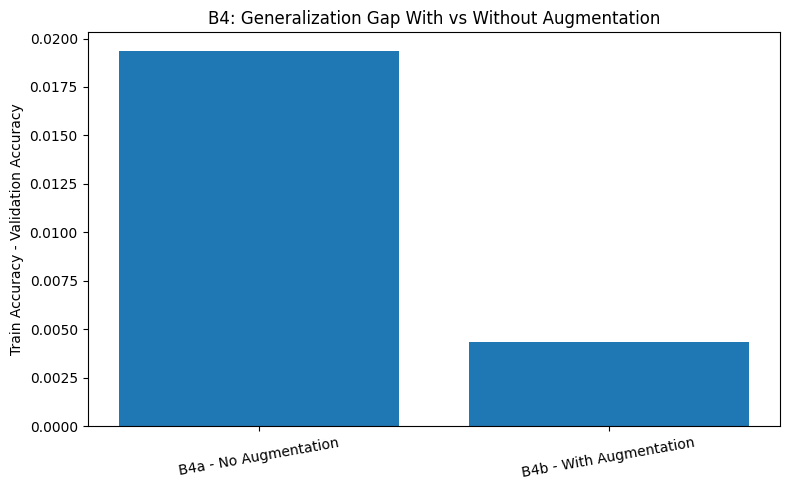

In [31]:
# Compare B4a and B4b results
best_epoch_b4a = int(np.argmin(history_b4a["val_loss"]))
best_epoch_b4b = int(np.argmin(history_b4b["val_loss"]))

b4_comparison = pd.DataFrame([
    {
        "Condition": "B4a - No Augmentation",
        "Best Val Accuracy": max(history_b4a["val_accuracy"]),
        "Final Train Accuracy": history_b4a["train_accuracy"][best_epoch_b4a],
        "Final Val Accuracy": history_b4a["val_accuracy"][best_epoch_b4a],
        "Test Accuracy": eval_b4a["accuracy"],
        "Test Macro F1": eval_b4a["macro_f1"]
    },
    {
        "Condition": "B4b - With Augmentation",
        "Best Val Accuracy": max(history_b4b["val_accuracy"]),
        "Final Train Accuracy": history_b4b["train_accuracy"][best_epoch_b4b],
        "Final Val Accuracy": history_b4b["val_accuracy"][best_epoch_b4b],
        "Test Accuracy": eval_b4b["accuracy"],
        "Test Macro F1": eval_b4b["macro_f1"]
    }
])

# Calculate train-validation accuracy gap
b4_comparison["Train-Val Accuracy Gap"] = (
    b4_comparison["Final Train Accuracy"]
    - b4_comparison["Final Val Accuracy"]
)

display(b4_comparison.round(4))

plt.figure(figsize=(8, 5))

plt.bar(
    b4_comparison["Condition"],
    b4_comparison["Train-Val Accuracy Gap"]
)

plt.ylabel("Train Accuracy - Validation Accuracy")
plt.title("B4: Generalization Gap With vs Without Augmentation")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [32]:

# Evaluate all experiments on the test set
eval_b2 = evaluate_model(model_b2, test_loader, device)
eval_b3 = evaluate_model(model_b3, test_loader, device)
eval_b4a = evaluate_model(model_b4a, test_loader, device)
eval_b4b = evaluate_model(model_b4b, test_loader_aug, device)

# Create the comparison table from experiment results
comparison = pd.DataFrame([
    {
        "Experiment": "B2",
        "Strategy": "Feature Extraction",
        "Augmentation": "No",
        "Best Val Accuracy": max(history_b2["val_accuracy"]),
        "Test Accuracy": eval_b2["accuracy"],
        "Test Macro F1": eval_b2["macro_f1"],
        "Training Time (s)": training_time_b2
    },
    {
        "Experiment": "B3",
        "Strategy": "Fine-Tuning",
        "Augmentation": "No",
        "Best Val Accuracy": max(history_b3["val_accuracy"]),
        "Test Accuracy": eval_b3["accuracy"],
        "Test Macro F1": eval_b3["macro_f1"],
        "Training Time (s)": training_time_b3
    },
    {
        "Experiment": "B4a",
        "Strategy": "Feature Extraction",
        "Augmentation": "No",
        "Best Val Accuracy": max(history_b4a["val_accuracy"]),
        "Test Accuracy": eval_b4a["accuracy"],
        "Test Macro F1": eval_b4a["macro_f1"],
        "Training Time (s)": training_time_b4a
    },
    {
        "Experiment": "B4b",
        "Strategy": "Feature Extraction",
        "Augmentation": "Yes",
        "Best Val Accuracy": max(history_b4b["val_accuracy"]),
        "Test Accuracy": eval_b4b["accuracy"],
        "Test Macro F1": eval_b4b["macro_f1"],
        "Training Time (s)": training_time_b4b
    }
])

# Display comparison table
print("Experiment Comparison")
display(
    comparison.sort_values(
        "Best Val Accuracy",
        ascending=False
    ).round(4)
)

# Identify all experiments tied for the highest validation accuracy
best_val_accuracy = comparison["Best Val Accuracy"].max()

best_results = comparison[
    comparison["Best Val Accuracy"] == best_val_accuracy
]

print("\nExperiment(s) with the highest validation accuracy:")
print(best_results["Experiment"].tolist())
print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")

print("\nDetails:")
display(best_results)

best_test_idx = comparison["Test Accuracy"].idxmax()
best_test_result = comparison.loc[best_test_idx]

print("\nHighest Test Accuracy (evaluation only):")
print("Experiment:", best_test_result["Experiment"])
print(f"Test Accuracy: {best_test_result['Test Accuracy']:.4f}")
print(f"Test Macro F1: {best_test_result['Test Macro F1']:.4f}")

Experiment Comparison


,Experiment,Strategy,Augmentation,Best Val Accuracy,Test Accuracy,Test Macro F1,Training Time (s)
0,B2,Feature Extraction,No,0.9833,0.9467,0.9466,181.6233
2,B4a,Feature Extraction,No,0.9833,0.9600,0.9601,183.2551
3,B4b,Feature Extraction,Yes,0.9799,0.9533,0.9537,267.5237
1,B3,Fine-Tuning,No,0.9732,0.9500,0.9497,117.6337



Experiment(s) with the highest validation accuracy:
['B2', 'B4a']
Best Validation Accuracy: 0.9833

Details:


,Experiment,Strategy,Augmentation,Best Val Accuracy,Test Accuracy,Test Macro F1,Training Time (s)
0,B2,Feature Extraction,No,0.983278,0.946667,0.946558,181.623316
2,B4a,Feature Extraction,No,0.983278,0.960000,0.960069,183.255100



Highest Test Accuracy (evaluation only):
Experiment: B4a
Test Accuracy: 0.9600
Test Macro F1: 0.9601


## 8. B5 EfficientNet-B0 Comparison

### Initialize EfficientNet-B0

In [33]:

# Load pretrained EfficientNet-B0
eff_weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model_b5 = models.efficientnet_b0(weights=eff_weights)

# Freeze all pretrained parameters
for param in model_b5.parameters():
    param.requires_grad = False

# Select the best experiment based on validation accuracy
best_val_accuracy = comparison["Best Val Accuracy"].max()

best_experiments = comparison.loc[
    comparison["Best Val Accuracy"] == best_val_accuracy,
    "Experiment"
].tolist()

print("Experiments with highest validation accuracy:", best_experiments)

validation_histories = {
    "B2": history_b2,
    "B3": history_b3,
    "B4a": history_b4a,
    "B4b": history_b4b
}

reference_strategies = {
    "B2": "Feature Extraction",
    "B3": "Progressive Fine-Tuning",
    "B4a": "Feature Extraction, No Augmentation",
    "B4b": "Feature Extraction, With Augmentation"
}

# Ties in validation accuracy are broken by the lowest validation loss.
selected_experiment = min(
    best_experiments,
    key=lambda name: min(validation_histories[name]["val_loss"])
)

reference_strategy = reference_strategies[selected_experiment]

print("Selected reference experiment:", selected_experiment)

# Unfreeze the final feature block only if B3 is selected
if selected_experiment == "B3":
    for param in model_b5.features[-1].parameters():
        param.requires_grad = True

# Replace the classifier for 10 classes
model_b5.classifier[1] = nn.Linear(
    model_b5.classifier[1].in_features,
    NUM_CLASSES
)

model_b5 = model_b5.to(device)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in model_b5.parameters()
        if p.requires_grad
    )
)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 160MB/s]

Experiments with highest validation accuracy: ['B2', 'B4a']
Selected reference experiment: B4a
Trainable parameters: 12810


### Configure B5 optimizer

In [34]:
if selected_experiment == "B3":
    optimizer_b5 = torch.optim.AdamW(
        [
            {
                "params": model_b5.features[-1].parameters(),
                "lr": 1e-4
            },
            {
                "params": model_b5.classifier.parameters(),
                "lr": 1e-3
            }
        ],
        weight_decay=1e-2
    )
    learning_rate_b5 = "features[-1]: 1e-4, classifier: 1e-3"
else:
    optimizer_b5 = torch.optim.AdamW(
        model_b5.classifier.parameters(),
        lr=1e-3,
        weight_decay=1e-2
    )
    learning_rate_b5 = 1e-3

# Define loss function
criterion_b5 = nn.CrossEntropyLoss()

print("Optimizer: AdamW")
print("Learning rate:", learning_rate_b5)
print("Weight decay: 1e-2")
print("Loss function: CrossEntropyLoss")

Optimizer: AdamW
Learning rate: 0.001
Weight decay: 1e-2
Loss function: CrossEntropyLoss


### Train and evaluate B5

In [35]:
train_loader_b5 = train_loader_aug if selected_experiment == "B4b" else train_loader

model_b5, history_b5, training_time_b5 = train_model(
    model=model_b5,
    train_loader=train_loader_b5,
    val_loader=val_loader,
    criterion=criterion_b5,
    optimizer=optimizer_b5,
    device=device,
    num_epochs=20,
    patience=4
)

print(f"B5 Training Time: {training_time_b5:.2f} seconds")

Model training mode: True
Epoch 01/20 | Train Loss: 0.9355 | Train Acc: 0.8268 | Val Loss: 0.2845 | Val Acc: 0.9666
Epoch 02/20 | Train Loss: 0.2257 | Train Acc: 0.9649 | Val Loss: 0.1611 | Val Acc: 0.9766
Epoch 03/20 | Train Loss: 0.1490 | Train Acc: 0.9699 | Val Loss: 0.1252 | Val Acc: 0.9766
Epoch 04/20 | Train Loss: 0.1163 | Train Acc: 0.9785 | Val Loss: 0.1041 | Val Acc: 0.9799
Epoch 05/20 | Train Loss: 0.0989 | Train Acc: 0.9807 | Val Loss: 0.0927 | Val Acc: 0.9866
Epoch 06/20 | Train Loss: 0.0829 | Train Acc: 0.9843 | Val Loss: 0.0849 | Val Acc: 0.9866
Epoch 07/20 | Train Loss: 0.0708 | Train Acc: 0.9885 | Val Loss: 0.0803 | Val Acc: 0.9833
Epoch 08/20 | Train Loss: 0.0590 | Train Acc: 0.9900 | Val Loss: 0.0743 | Val Acc: 0.9866
Epoch 09/20 | Train Loss: 0.0594 | Train Acc: 0.9857 | Val Loss: 0.0704 | Val Acc: 0.9900
Epoch 10/20 | Train Loss: 0.0496 | Train Acc: 0.9936 | Val Loss: 0.0672 | Val Acc: 0.9900
Epoch 11/20 | Train Loss: 0.0471 | Train Acc: 0.9928 | Val Loss: 0.0659 | 

In [36]:
eval_b5 = evaluate_model(model_b5, test_loader, device)

print("B5 - EfficientNet-B0 Test Results")
print(f"Test Accuracy: {eval_b5['accuracy']:.4f}")
print(f"Test Macro F1: {eval_b5['macro_f1']:.4f}")
print(f"Training Time: {training_time_b5:.2f} seconds")

# Count total and trainable parameters
total_params_b5 = sum(
    p.numel() for p in model_b5.parameters()
)

trainable_params_b5 = sum(
    p.numel() for p in model_b5.parameters()
    if p.requires_grad
)

print(f"Total Parameters: {total_params_b5:,}")
print(f"Trainable Parameters: {trainable_params_b5:,}")

B5 - EfficientNet-B0 Test Results
Test Accuracy: 0.9833
Test Macro F1: 0.9833
Training Time: 185.09 seconds
Total Parameters: 4,020,358
Trainable Parameters: 12,810


## 9. Experiment Result Summary



### Define result-table helper

In [37]:

def result_row(
    name,
    model,
    history,
    training_time,
    evaluation,
    learning_rate,
    strategy
):
    best_val_loss_epoch = min(
        range(len(history["val_loss"])),
        key=lambda i: history["val_loss"][i]
    )

    return {
        "Experiment": name,
        "Strategy": strategy,
        "Trainable Parameters": sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        ),
        "Learning Rate": learning_rate,
        "Converged Epochs": best_val_loss_epoch + 1,
        "Epochs Run": len(history["train_loss"]),
        "Training Time (s)": round(float(training_time), 3),
        "Best Validation Loss": history["val_loss"][best_val_loss_epoch],
        "Validation Accuracy at Best Loss": history["val_accuracy"][best_val_loss_epoch],
        "Best Validation Accuracy": max(history["val_accuracy"]),
        "Test Accuracy": evaluation["accuracy"],
        "Test Macro F1": evaluation["macro_f1"]
    }

### Collect test metrics and build the result table

In [38]:

# Evaluate all experiments on the same test split
eval_b1 = evaluate_model(model_b1, test_loader, device)
eval_b2 = evaluate_model(model_b2, test_loader, device)
eval_b3 = evaluate_model(model_b3, test_loader, device)
eval_b4a = evaluate_model(model_b4a, test_loader, device)
eval_b4b = evaluate_model(model_b4b, test_loader_aug, device)
eval_b5 = evaluate_model(model_b5, test_loader, device)

# Collect results for B1-B5
results = [
    result_row(
        "B1", model_b1, history_b1, training_time_b1,
        eval_b1, learning_rate=1e-3,
        strategy="Training from Scratch"
    ),
    result_row(
        "B2", model_b2, history_b2, training_time_b2,
        eval_b2, learning_rate=1e-3,
        strategy="Feature Extraction"
    ),
    result_row(
        "B3", model_b3, history_b3, training_time_b3,
        eval_b3, learning_rate="layer4: 1e-4, fc: 1e-3",
        strategy="Progressive Fine-Tuning"
    ),
    result_row(
        "B4a", model_b4a, history_b4a, training_time_b4a,
        eval_b4a, learning_rate=1e-3,
        strategy="Feature Extraction, No Augmentation"
    ),
    result_row(
        "B4b", model_b4b, history_b4b, training_time_b4b,
        eval_b4b, learning_rate=1e-3,
        strategy="Feature Extraction, With Augmentation"
    ),
    result_row(
        "B5", model_b5, history_b5, training_time_b5,
        eval_b5, learning_rate=learning_rate_b5,
        strategy=f"EfficientNet-B0 {reference_strategy}"
    )
]

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Test Macro F1",
        ascending=False
    ).round(4)
)

,Experiment,Strategy,Trainable Parameters,Learning Rate,Converged Epochs,Epochs Run,Training Time (s),Best Validation Loss,Validation Accuracy at Best Loss,Best Validation Accuracy,Test Accuracy,Test Macro F1
5,B5,"EfficientNet-B0 Feature Extraction, No Augment...",12810,0.001,20,20,185.093,0.0561,0.9900,0.9900,0.9833,0.9833
3,B4a,"Feature Extraction, No Augmentation",5130,0.001,20,20,183.255,0.0853,0.9799,0.9833,0.9600,0.9601
4,B4b,"Feature Extraction, With Augmentation",5130,0.001,19,20,267.524,0.0964,0.9799,0.9799,0.9533,0.9537
2,B3,Progressive Fine-Tuning,8398858,"layer4: 1e-4, fc: 1e-3",9,13,117.634,0.0777,0.9732,0.9732,0.9500,0.9497
1,B2,Feature Extraction,5130,0.001,19,20,181.623,0.0862,0.9799,0.9833,0.9467,0.9466
0,B1,Training from Scratch,11181642,0.001,2,6,63.277,1.9409,0.2910,0.3645,0.2467,0.2253


In [39]:

reference_runs = {
    "B2": (model_b2, eval_b2, training_time_b2),
    "B3": (model_b3, eval_b3, training_time_b3),
    "B4a": (model_b4a, eval_b4a, training_time_b4a),
    "B4b": (model_b4b, eval_b4b, training_time_b4b)
}

reference_model, reference_eval, reference_time = reference_runs[selected_experiment]

b5_comparison = pd.DataFrame([
    {
        "Model": f"{selected_experiment} - ResNet18 {reference_strategy}",
        "Total Parameters": sum(
            p.numel() for p in reference_model.parameters()
        ),
        "Trainable Parameters": sum(
            p.numel() for p in reference_model.parameters()
            if p.requires_grad
        ),
        "Test Macro F1": reference_eval["macro_f1"],
        "Training Time (s)": reference_time,
    },
    {
        "Model": "B5 - EfficientNet-B0",
        "Total Parameters": sum(
            p.numel() for p in model_b5.parameters()
        ),
        "Trainable Parameters": sum(
            p.numel() for p in model_b5.parameters()
            if p.requires_grad
        ),
        "Test Macro F1": eval_b5["macro_f1"],
        "Training Time (s)": training_time_b5,
    },
])

display(b5_comparison.round(4))

,Model,Total Parameters,Trainable Parameters,Test Macro F1,Training Time (s)
0,"B4a - ResNet18 Feature Extraction, No Augmenta...",11181642,5130,0.9601,183.2551
1,B5 - EfficientNet-B0,4020358,12810,0.9833,185.0933


## 10. Training & Validation Curves



### Training and validation loss curves

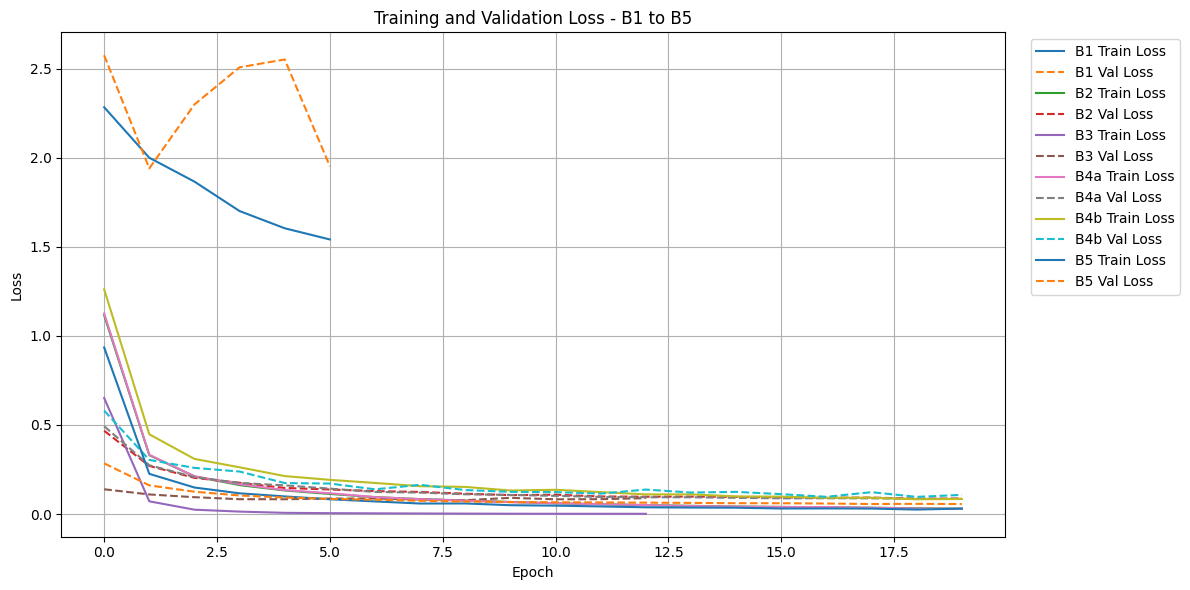

In [40]:

plt.figure(figsize=(12, 6))

histories = {
    "B1": history_b1,
    "B2": history_b2,
    "B3": history_b3,
    "B4a": history_b4a,
    "B4b": history_b4b,
    "B5": history_b5,
}

for name, history in histories.items():
    plt.plot(history["train_loss"], label=f"{name} Train Loss")
    plt.plot(history["val_loss"], linestyle="--", label=f"{name} Val Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss - B1 to B5")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

### Training and validation loss curves - B1, B2, and B3

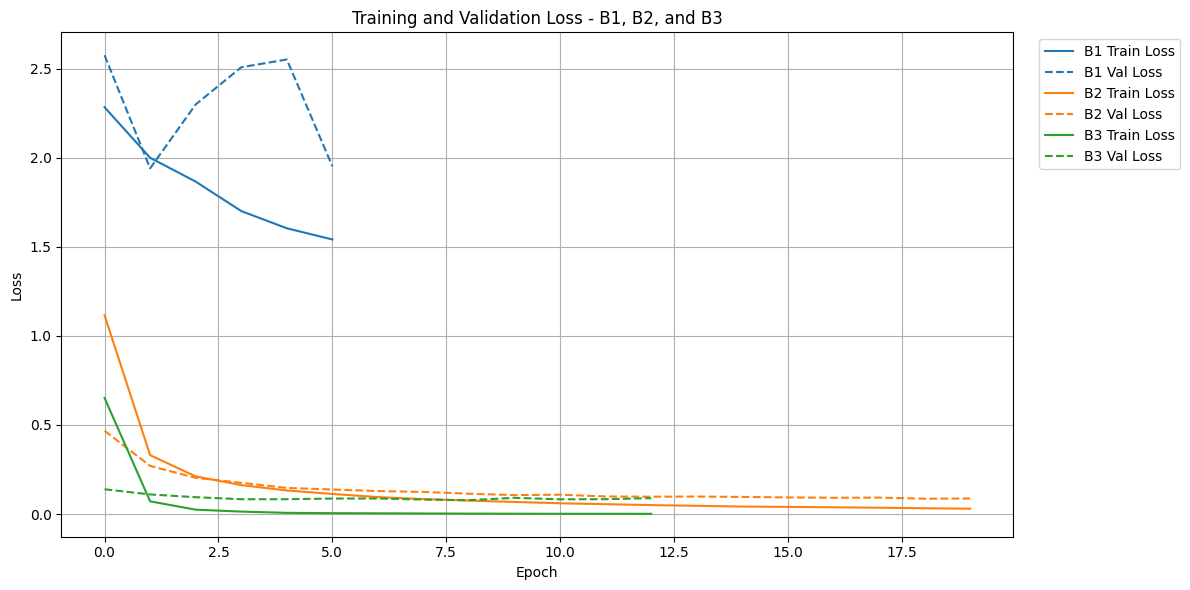

In [41]:

plt.figure(figsize=(12, 6))

for name in ["B1", "B2", "B3"]:
    history = histories[name]
    train_line, = plt.plot(history["train_loss"], label=f"{name} Train Loss")
    plt.plot(
        history["val_loss"],
        linestyle="--",
        color=train_line.get_color(),
        label=f"{name} Val Loss"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss - B1, B2, and B3")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()


### Training and validation accuracy curves

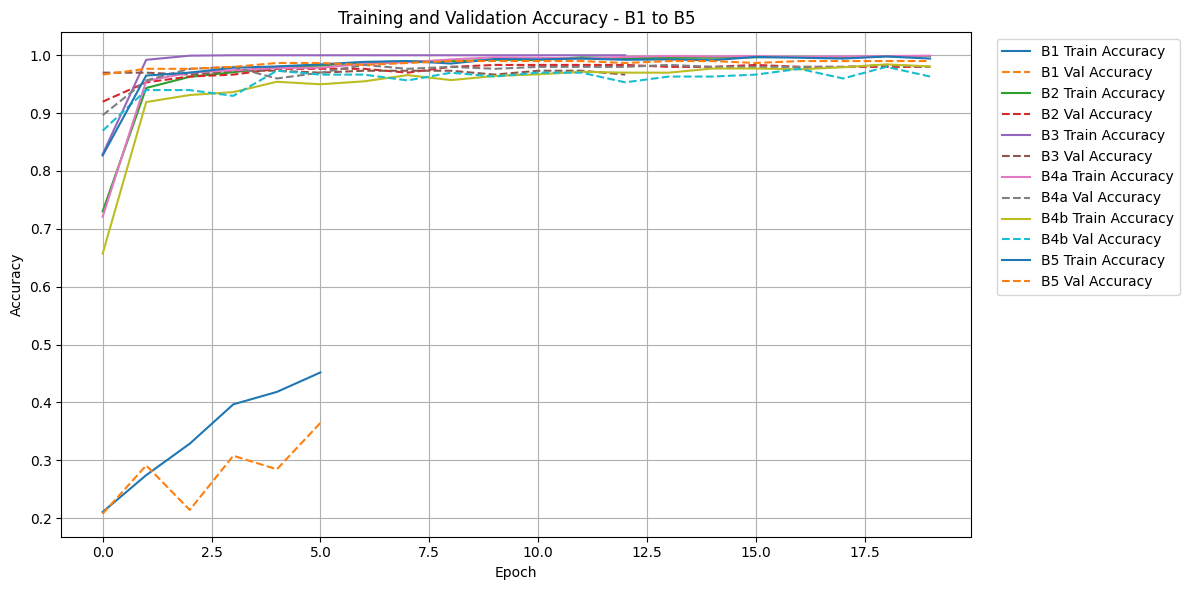

In [42]:

plt.figure(figsize=(12, 6))

for name, history in histories.items():
    plt.plot(history["train_accuracy"], label=f"{name} Train Accuracy")
    plt.plot(
        history["val_accuracy"],
        linestyle="--",
        label=f"{name} Val Accuracy"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy - B1 to B5")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

## 11. Failure Analysis



In [59]:
class_names = selected_classes

model_candidates = {
    "B1": (model_b1, history_b1, eval_b1),
    "B2": (model_b2, history_b2, eval_b2),
    "B3": (model_b3, history_b3, eval_b3),
    "B4a": (model_b4a, history_b4a, eval_b4a),
    "B4b": (model_b4b, history_b4b, eval_b4b),
    "B5": (model_b5, history_b5, eval_b5)
}
best_model_id = max(
    model_candidates,
    key=lambda k: (
        max(model_candidates[k][1]["val_accuracy"]),
        -min(model_candidates[k][1]["val_loss"])
    )
)
best_model, best_history, best_eval = model_candidates[best_model_id]
print("Best model selected by validation accuracy:", best_model_id)

y_true = best_eval["y_true"]
y_pred = best_eval["y_pred"]
y_prob = best_eval["y_prob"]
wrong_indices = np.where(y_true != y_pred)[0]
confidence = y_prob.max(axis=1)


Best model selected by validation accuracy: B5


In [60]:
wrong_indices = np.where(y_true != y_pred)[0]
confidence = y_prob.max(axis=1)

failure_df = pd.DataFrame({
    "test_index": wrong_indices,
    "true_label": [class_names[y_true[i]] for i in wrong_indices],
    "predicted_label": [class_names[y_pred[i]] for i in wrong_indices],
    "confidence_score": confidence[wrong_indices],
    "true_class_probability": y_prob[wrong_indices, y_true[wrong_indices]]
})

print(failure_df)
print("Number of rows:", len(failure_df))

   test_index  true_label predicted_label  confidence_score  \
0          36  Abyssinian          Bengal          0.562905   
1          67      Bengal      Abyssinian          0.826148   
2         118     Siamese          Birman          0.816502   
3         127         Pug           Boxer          0.989235   
4         242     Siamese      Abyssinian          0.684792   

   true_class_probability  
0                0.427395  
1                0.171961  
2                0.174234  
3                0.005479  
4                0.180742  
Number of rows: 5


### Visualize misclassified test images

Total test errors: 5 | Errors shown: 5


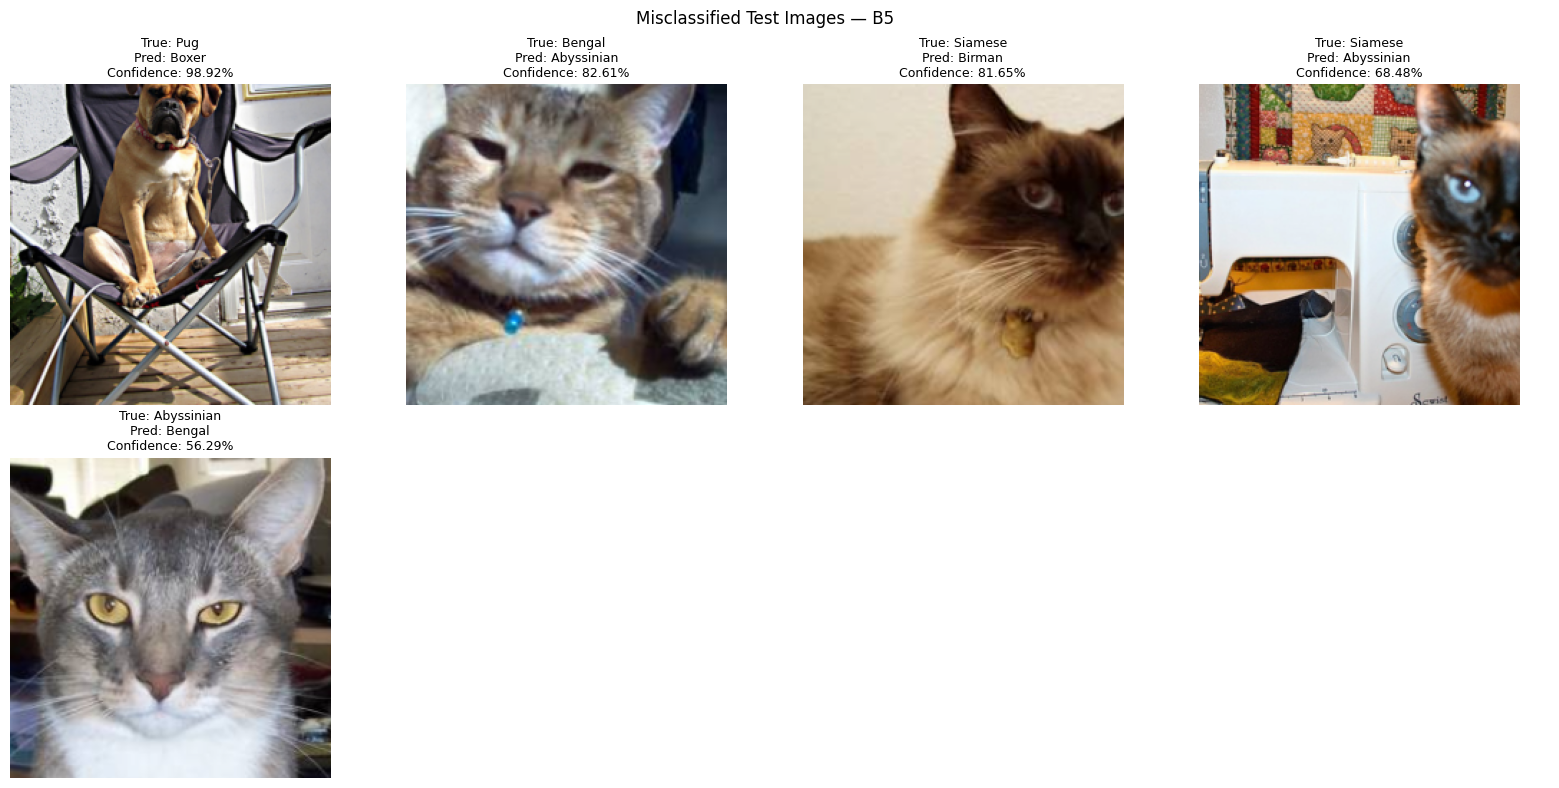

In [61]:
selected_error_indices = wrong_indices[np.argsort(-confidence[wrong_indices])][:8]
print("Total test errors:", len(wrong_indices), "| Errors shown:", len(selected_error_indices))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
for ax in axes:
    ax.axis("off")
for ax, idx in zip(axes, selected_error_indices):
    image, _ = test_dataset[idx]
    image_vis = image.detach().cpu().permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image_vis = np.clip(image_vis * std + mean, 0, 1)
    ax.imshow(image_vis)
    ax.set_title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}\nConfidence: {confidence[idx]:.2%}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Misclassified Test Images — {best_model_id}")
plt.tight_layout()
plt.show()



### Create failure-analysis table

In [62]:
failure_df = pd.DataFrame([
    {
        "test_index": int(idx),
        "true_label": class_names[y_true[idx]],
        "predicted_label": class_names[y_pred[idx]],
        "confidence_score": float(confidence[idx]),
        "true_class_probability": float(y_prob[idx, y_true[idx]]),
    } for idx in selected_error_indices
])
display(failure_df.round(4))



,test_index,true_label,predicted_label,confidence_score,true_class_probability
0,127,Pug,Boxer,0.9892,0.0055
1,67,Bengal,Abyssinian,0.8261,0.1720
2,118,Siamese,Birman,0.8165,0.1742
3,242,Siamese,Abyssinian,0.6848,0.1807
4,36,Abyssinian,Bengal,0.5629,0.4274


### Export raw metrics and experiment settings

In [64]:

from pathlib import Path
import json
import pandas as pd

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results = pd.DataFrame(results)

results.to_csv(
    OUTPUT_DIR / "raw_metrics.csv",
    index=False
)

results.to_json(
    OUTPUT_DIR / "raw_metrics.json",
    orient="records",
    indent=2
)

failure_df = pd.DataFrame(failure_df)
failure_df.to_csv(
    OUTPUT_DIR / "failure_analysis.csv",
    index=False
)

b4_comparison = pd.DataFrame(b4_comparison)
b4_comparison.to_csv(
    OUTPUT_DIR / "b4_augmentation_comparison.csv",
    index=False
)

b5_comparison = pd.DataFrame(b5_comparison)
b5_comparison.to_csv(
    OUTPUT_DIR / "b5_architecture_comparison.csv",
    index=False
)

training_history = pd.DataFrame([
    {
        "experiment": name,
        "epoch": epoch + 1,
        "train_loss": history["train_loss"][epoch],
        "val_loss": history["val_loss"][epoch],
        "train_accuracy": history["train_accuracy"][epoch],
        "val_accuracy": history["val_accuracy"][epoch]
    }
    for name, history in histories.items()
    for epoch in range(len(history["train_loss"]))
])
training_history.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

experiment_settings = {
    "seed": int(SEED),
    "device": str(device),
    "dataset": "Oxford-IIIT Pet",
    "classes": selected_classes,
    "number_of_classes": len(selected_classes),
    "split": (
        "Stratified 70/15/15 split from the combined official "
        "trainval and test sets"
    ),
    "split_sizes": {
        "train": len(train_loader.dataset),
        "validation": len(val_loader.dataset),
        "test": len(test_loader.dataset)
    },
    "input_size": "224x224",
    "batch_size": int(BATCH_SIZE),
    "optimizer": "AdamW",
    "loss": "CrossEntropyLoss",
    "max_epochs": 20,
    "early_stopping_patience": 4,
    "pretrained_weights": {
        "B1": None,
        "B2-B4": "ResNet18_Weights.IMAGENET1K_V1",
        "B5": "EfficientNet_B0_Weights.IMAGENET1K_V1"
    },
    "strategies": {
        "B1": "ResNet18 trained from scratch",
        "B2": "ResNet18 feature extraction",
        "B3": "ResNet18 progressive fine-tuning",
        "B4a": "ResNet18 feature extraction without augmentation",
        "B4b": "ResNet18 feature extraction with augmentation",
        "B5": f"EfficientNet-B0 {reference_strategy.lower()}"
    },
    "b5_strategy": reference_strategy,
    "b5_reference_experiment": selected_experiment,
    "test_evaluation": (
        "Internal test split; not the untouched official Oxford-IIIT Pet test split"
    )
}

with open(
    OUTPUT_DIR / "experiment_settings.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        experiment_settings,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Export completed successfully!")
print("\nExported files:")

for output_file in sorted(OUTPUT_DIR.iterdir()):
    if output_file.is_file():
        print(
            f"- {output_file} "
            f"({output_file.stat().st_size:,} bytes)"
        )

print("\nExperiment metrics shape:", results.shape)
print("Failure analysis shape:", failure_df.shape)
print("B4 comparison shape:", b4_comparison.shape)
print("B5 comparison shape:", b5_comparison.shape)
print("Training history shape:", training_history.shape)

Export completed successfully!

Exported files:
- outputs/b4_augmentation_comparison.csv (379 bytes)
- outputs/b5_architecture_comparison.csv (254 bytes)
- outputs/experiment_settings.json (1,262 bytes)
- outputs/failure_analysis.csv (371 bytes)
- outputs/raw_metrics.csv (1,142 bytes)
- outputs/raw_metrics.json (2,578 bytes)
- outputs/training_history.csv (8,159 bytes)

Experiment metrics shape: (6, 12)
Failure analysis shape: (5, 5)
B4 comparison shape: (2, 7)
B5 comparison shape: (2, 5)
Training history shape: (99, 6)


In [65]:
import shutil

zip_path = shutil.make_archive(
    "experiment_outputs",
    "zip",
    root_dir="outputs"
)

print("ZIP created:", zip_path)

ZIP created: /content/experiment_outputs.zip


## 13. Reproducibility and Experiment Settings



In [66]:

print("Seed:", SEED)
print("Device:", device)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Optimizer: AdamW")
print("Loss function: CrossEntropyLoss")
print("Maximum epochs: 20")
print("Early stopping patience: 4")
print("Input size: 224 x 224")

Seed: 42
Device: cuda
Batch size: 32
Number of classes: 10
Optimizer: AdamW
Loss function: CrossEntropyLoss
Maximum epochs: 20
Early stopping patience: 4
Input size: 224 x 224
